
### **Task 1: Planning Data and Objective Construction**


**Scaling** (min–max scaling is computed over the 2,000-cell planning sample, where $q$ denotes all values of one variable and $q_i$ one value of that variable):

$$z(q_i) = \frac{q_i - \min(q)}{\max(q) - \min(q)}$$

This scaling is applied to Elevation, Slope, Horizontal_Distance_To_Hydrology and Horizontal_Distance_To_Roadways, giving $z(elev_i)$, $z(slope_i)$, $z(hydro_i)$, $z(road_i)$.

The three quantities are then:

$$E_i = 100\,[\,0.6\,(1-z(road_i)) + 0.4\,(1-z(slope_i))\,]$$
$$V_i = 100\,[\,0.6\,(1-z(hydro_i)) + 0.4\,z(elev_i)\,]$$
$$C_i = 10 + 5\,z(road_i) + 5\,z(elev_i)$$

Full floating-point precision is kept throughout; rounding is applied **only** to displayed tables and plots.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from scipy.stats import binom
import time

DATA_FILE     = "../data/COMP663_Assignment3_PlanningData_2000.csv"   
N_CELLS       = 2000
BUDGET_FRAC   = 0.50      # Constraint 2
PRESERVE_FRAC = 0.20      # Constraint 1

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

Loading and verifying the supplied 2,000-cell planning dataset `COMP663_Assignment3_PlanningData_2000.csv`, so min–max scaling is computed over exactly these 2,000 cells.

In [3]:
cells = pd.read_csv(DATA_FILE)

needed = ["Cell_ID","Elevation","Slope","Horizontal_Distance_To_Hydrology",
          "Horizontal_Distance_To_Roadways","Cover_Type"]
assert len(cells) == N_CELLS, f"expected {N_CELLS} cells, got {len(cells)}"
assert cells[needed].notna().all().all(), "missing values in required columns"
assert cells["Cell_ID"].is_unique, "Cell_ID is not unique"
for c in ["Elevation","Slope","Horizontal_Distance_To_Hydrology","Horizontal_Distance_To_Roadways"]:
    assert cells[c].max() > cells[c].min(), f"{c} is constant: min-max scaling undefined"
print(f"Loaded {cells.shape[0]:,} cells x {cells.shape[1]} columns; "
      f"missing values = {int(cells.isna().sum().sum())}, duplicate rows = {int(cells.duplicated().sum())}, "
      f"Cell_ID {cells.Cell_ID.min()}..{cells.Cell_ID.max()}")
cells[needed[1:]].describe().T[["count","min","max","mean","std"]]

Loaded 2,000 cells x 16 columns; missing values = 0, duplicate rows = 0, Cell_ID 1..2000


,count,min,max,mean,std
Elevation,"2,000.0000","1,929.0000","3,777.0000","2,961.3025",277.3232
Slope,"2,000.0000",0.0000,51.0000,14.1395,7.5712
Horizontal_Distance_To_Hydrology,"2,000.0000",0.0000,"1,207.0000",270.2555,213.6805
Horizontal_Distance_To_Roadways,"2,000.0000",0.0000,"6,993.0000","2,365.2370","1,535.1819"
Cover_Type,"2,000.0000",1.0000,5.0000,1.8020,0.8644


### 2. Cover-type composition

In [4]:
ct = cells["Cover_Type"].value_counts().sort_index()
comp = pd.DataFrame({"cells": ct, "percent": 100*ct/len(cells)})
comp.loc["Total"] = comp.sum()
comp.index.name = "Cover_Type"
comp.style.format({"cells":"{:,.0f}", "percent":"{:.2f}"})

,cells,percent
Cover_Type,,
1,735,36.75
2,"1,110",55.50
3,36,1.80
4,54,2.70
5,65,3.25
Total,"2,000",100.00


### 3. Min–max scaling and construction of $E_i$, $V_i$, $C_i$

In [5]:
def minmax(s):
    s = s.astype(float)
    return (s - s.min()) / (s.max() - s.min())

cells["z_elev"]  = minmax(cells["Elevation"])
cells["z_slope"] = minmax(cells["Slope"])
cells["z_hydro"] = minmax(cells["Horizontal_Distance_To_Hydrology"])
cells["z_road"]  = minmax(cells["Horizontal_Distance_To_Roadways"])

cells["E"] = 100 * (0.6*(1 - cells["z_road"])  + 0.4*(1 - cells["z_slope"]))
cells["V"] = 100 * (0.6*(1 - cells["z_hydro"]) + 0.4*cells["z_elev"])
cells["C"] = 10 + 5*cells["z_road"] + 5*cells["z_elev"]

# range checks (full precision, small tolerance only for float error)
for z in ["z_elev","z_slope","z_hydro","z_road"]:
    assert cells[z].min() == 0.0 and cells[z].max() == 1.0, z
assert cells["E"].between(0, 100).all() and cells["V"].between(0, 100).all()
assert cells["C"].between(10, 20).all()
print("All range checks passed: z in [0,1], E and V in [0,100], C in [10,20].")
cells[["Cell_ID","Cover_Type","E","V","C"]].head(10).round(4)

All range checks passed: z in [0,1], E and V in [0,100], C in [10,20].


,Cell_ID,Cover_Type,E,V,C
0,1,1,43.7838,71.2045,17.6212
1,2,2,48.3670,62.1976,16.1318
2,3,5,49.5637,91.7771,16.4008
3,4,2,56.8678,68.9624,16.1463
4,5,1,63.6162,68.5234,16.2741
5,6,2,62.2636,40.7727,15.0674
6,7,2,72.2260,64.1130,13.2548
7,8,2,55.0927,81.2987,15.6203
8,9,1,56.8799,78.6168,16.7464
9,10,1,58.8129,71.9312,16.3109


### 4. Summary statistics and distributions

In [6]:
stats = cells[["E","V","C"]].agg(["count","min","max","mean","median","std"]).T
stats["q25"] = cells[["E","V","C"]].quantile(0.25)
stats["q75"] = cells[["E","V","C"]].quantile(0.75)
stats = stats[["count","min","q25","median","q75","max","mean","std"]]
print(f"Correlations: corr(E,V)={cells.E.corr(cells.V):.3f}, "
      f"corr(E,C)={cells.E.corr(cells.C):.3f}, corr(V,C)={cells.V.corr(cells.C):.3f}")
stats.round(4)

Correlations: corr(E,V)=-0.083, corr(E,C)=-0.759, corr(V,C)=0.247


,count,min,q25,median,q75,max,mean,std
E,"2,000.0000",27.3839,59.8181,70.2377,78.8984,97.1186,68.6164,13.2370
V,"2,000.0000",24.5887,62.0066,70.0752,76.8124,92.0346,68.9098,10.6451
C,"2,000.0000",10.0887,13.4753,14.4490,15.5621,18.6089,14.4842,1.5322


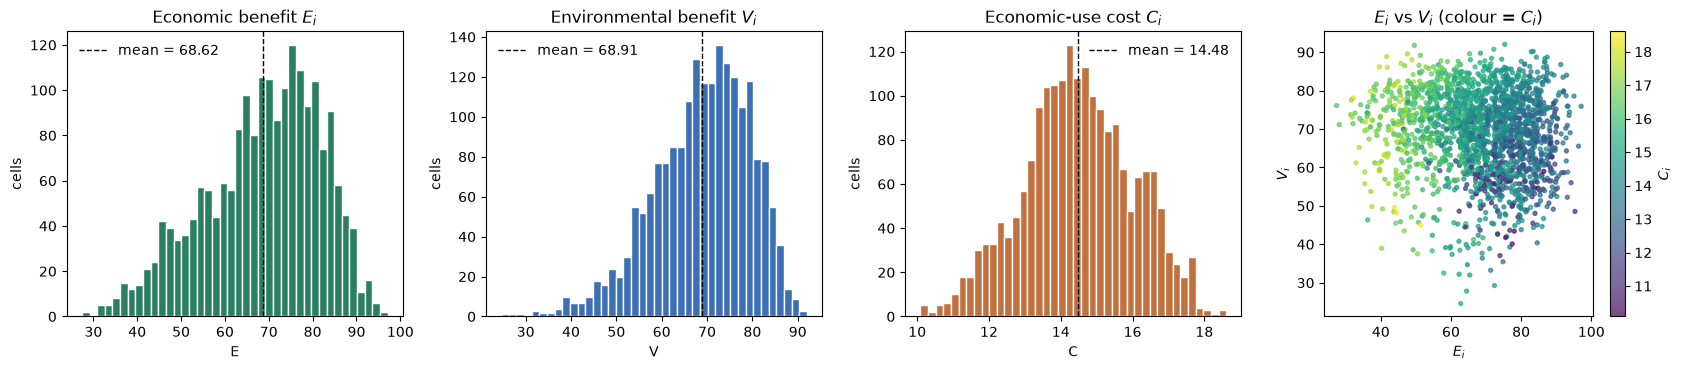

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, col, colour, lab in zip(ax[:3], ["E","V","C"], ["#2a7f62","#3b6fb6","#c2703d"],
                               ["Economic benefit $E_i$","Environmental benefit $V_i$","Economic-use cost $C_i$"]):
    a.hist(cells[col], bins=40, color=colour, edgecolor="white")
    a.axvline(cells[col].mean(), color="k", ls="--", lw=1, label=f"mean = {cells[col].mean():.2f}")
    a.set_title(lab); a.set_xlabel(col); a.set_ylabel("cells"); a.legend(frameon=False)
sc = ax[3].scatter(cells["E"], cells["V"], c=cells["C"], s=8, cmap="viridis", alpha=.7)
ax[3].set_xlabel("$E_i$"); ax[3].set_ylabel("$V_i$"); ax[3].set_title("$E_i$ vs $V_i$ (colour = $C_i$)")
plt.colorbar(sc, ax=ax[3], label="$C_i$")
plt.tight_layout(); plt.savefig("../figures/1_eco_use_cost", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
by_type = cells.groupby("Cover_Type")[["E","V","C"]].agg(["mean","std"]).round(3)
by_type

E               V               C       
              mean     std    mean     std    mean    std
Cover_Type                                               
1          67.1830 12.9680 72.5080 10.1170 15.1080 1.1400
2          69.2410 13.4840 66.5500 10.1830 14.1460 1.5330
3          76.0350  9.4910 65.6230 10.2450 13.0510 1.2770
4          76.8890  7.3260 63.0150  6.2880 12.0080 0.6750
5          63.1780 12.2750 75.2330 12.5460 16.0620 1.0680

### 5. Total economic-use cost and budget (Constraint 2)

Budget $B = 0.5\sum_{i=1}^{2000} C_i$.

In [9]:
total_cost = cells["C"].sum()
budget     = BUDGET_FRAC * total_cost
print(f"Total cost of using all {N_CELLS:,} cells : {total_cost:,.4f}")
print(f"Budget B (50% of total)              : {budget:,.4f}")
print(f"Mean cost per cell                   : {cells['C'].mean():.4f}")


Total cost of using all 2,000 cells : 28,968.3448
Budget B (50% of total)              : 14,484.1724
Mean cost per cell                   : 14.4842


### 6. Preview of Constraint 1 (preservation quotas)
Minimum preserved cells per cover type $= \lceil 0.2\,n_t\rceil$ (ceiling), used in the optimisation tasks.

In [10]:
quota = pd.DataFrame({"cells_n_t": ct})
quota["min_preserved"] = np.ceil(PRESERVE_FRAC * quota["cells_n_t"] - 1e-12).astype(int)  # tolerance guards float error
quota["max_economic"]  = quota["cells_n_t"] - quota["min_preserved"]
quota.loc["Total"] = quota.sum()
assert (quota.loc[ct.index, "min_preserved"] == -(-ct // 5)).all()   # cross-check with integer ceiling
quota

,cells_n_t,min_preserved,max_economic
Cover_Type,,,
1,735,147,588
2,1110,222,888
3,36,8,28
4,54,11,43
5,65,13,52
Total,2000,401,1599


### **Task 2: Problem Representation and Feasibility Design**

#### 2.0 Formulation being represented

Let $x_i\in\{0,1\}$ for each of the $n=2000$ cells, where $x_i=1$ means *economic use* and $x_i=0$ means *preserved for environmental use*. Let $T_t$ be the set of cells of cover type $t$, with $n_t=|T_t|$ and required preservation $r_t=\lceil 0.2\,n_t\rceil$.

$$\max_{x}\; f_1(x)=\sum_{i=1}^{n}E_i\,x_i \qquad\text{and}\qquad \max_{x}\; f_2(x)=\sum_{i=1}^{n}V_i\,(1-x_i)$$

subject to

$$\underbrace{\sum_{i=1}^{n}C_i\,x_i\;\le\;B=0.5\sum_{i=1}^{n}C_i}_{\text{budget}}\qquad\qquad \underbrace{\sum_{i\in T_t}(1-x_i)\;\ge\;r_t\quad\forall t}_{\text{preservation}}\qquad\qquad x_i\in\{0,1\}.$$

Each cell contributes to exactly one objective: $E_i$ if it is used economically, or $V_i$ if it is preserved. This is what makes the two objectives compete. Cost $C_i$ appears only in the budget constraint and is not a third objective.

### 2.1 Size of the search space and why exhaustive enumeration is infeasible

Every cell has two independent options, so the number of candidate allocations is

$$|\mathcal X| = \underbrace{2\times 2\times\cdots\times 2}_{2000\text{ times}} = 2^{2000}\approx 10^{602}.$$

Three points make enumeration hopeless:

1. **Scale.** $2^{2000}$ has 603 decimal digits. Adding one cell doubles the space, so growth is exponential in $n$.

2. **Cost per candidate.** Evaluating one candidate means summing over 2,000 cells (objectives, cost, five type counts), i.e. $O(n)$ work, so full enumeration is $O(n\,2^n)$.

3. **The constraints do not rescue us.** The feasible set is only a subset of $\mathcal X$. As Section 2.3 shows empirically and analytically, roughly half of all uniformly random allocations already satisfy both constraints, so the feasible region is still of order $10^{601}$. Also, a bi-objective problem asks for a whole set of non-dominated trade-offs, which would need every feasible candidate to be compared, not just one optimum.

The tables and plot below make the scale concrete.

In [11]:
n = N_CELLS
digits = str(2**n)                                   # exact big integer
print(f"|X| = 2^{n} = {digits[0]}.{digits[1:6]} x 10^{len(digits)-1}   ({len(digits)} decimal digits)")

RATE = 1e9                      # candidate evaluations per second (optimistic for Python)
SEC_PER_YEAR = 365.25 * 24 * 3600

def fmt_time(log10_sec):
    log10_years = log10_sec - math.log10(SEC_PER_YEAR)
    if log10_years < 0:   return f"{10**log10_sec:,.3g} seconds"
    if log10_years < 15:  return f"{10**log10_years:,.3g} years"
    return f"10^{log10_years:.1f} years"

rows = []
for k in [10, 20, 30, 40, 50, 60, 100, 2000]:
    log10_sol = k * math.log10(2)
    rows.append({"n cells": k,
                 "2^n candidates": f"{2**k:,}" if k <= 60 else f"10^{log10_sol:.1f}",
                 f"time at {RATE:.0e} evals/s": fmt_time(log10_sol - math.log10(RATE))})
display(pd.DataFrame(rows).set_index("n cells"))

# Physical bound: every atom in the observable universe (~1e80) evaluating 1e12 candidates/s
# for the whole age of the universe (~4.35e17 s)
log10_max_evals = 80 + 12 + math.log10(4.35e17)
log10_space = n * math.log10(2)
print(f"Upper bound on evaluations physically conceivable ~ 10^{log10_max_evals:.1f}")
print(f"Search space exceeds that bound by a factor of ~ 10^{log10_space - log10_max_evals:.0f}")

|X| = 2^2000 = 1.14813 x 10^602   (603 decimal digits)


,2^n candidates,time at 1e+09 evals/s
n cells,,
10,"1,024",1.02e-06 seconds
20,"1,048,576",0.00105 seconds
30,"1,073,741,824",1.07 seconds
40,"1,099,511,627,776",1.1e+03 seconds
50,"1,125,899,906,842,624",1.13e+06 seconds
60,"1,152,921,504,606,846,976",36.5 years
100,10^30.1,4.02e+13 years
2000,10^602.1,10^585.6 years


Upper bound on evaluations physically conceivable ~ 10^109.6
Search space exceeds that bound by a factor of ~ 10^492


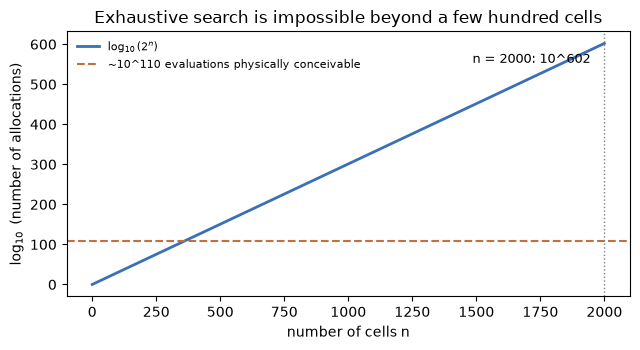

In [12]:
ks = np.arange(0, n + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ks, ks * math.log10(2), color="#3b6fb6", lw=2, label=r"$\log_{10}(2^n)$")
ax.axhline(log10_max_evals, color="#c2703d", ls="--", label=f"~10^{log10_max_evals:.0f} evaluations physically conceivable")
ax.axvline(n, color="grey", ls=":", lw=1)
ax.annotate(f"n = {n}: 10^{log10_space:.0f}", (n, log10_space), textcoords="offset points",
            xytext=(-95, -14), fontsize=9)
ax.set_xlabel("number of cells n"); ax.set_ylabel(r"$\log_{10}$ (number of allocations)")
ax.set_title("Exhaustive search is impossible beyond a few hundred cells")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout();plt.savefig("../figures/2_Exhaustive search", dpi=300, bbox_inches="tight")
plt.show()

### 2.2 Solution representation and decoding

**Representation.** A candidate solution is a **binary vector** $x\in\{0,1\}^{2000}$ (a NumPy array of length 2000). Position $j$ of the vector refers to the $j$-th row of the planning dataset, i.e. cell `Cell_ID = j+1`, so the vector is always aligned with the arrays $E$, $V$, $C$ and the cover-type labels.

**Decoding.**
- $x_j = 1$: the cell is allocated to **economic use** and contributes $E_j$ to $f_1$ and $C_j$ to the budget.
- $x_j = 0$: the cell is **preserved for environmental use** and contributes $V_j$ to $f_2$ and counts toward its cover type's preservation total.

The two land-use sets are $S_E=\{j:x_j=1\}$ and $S_P=\{j:x_j=0\}$. They are disjoint and cover all cells, so the "each cell is either economic or preserved" rule holds automatically for any binary vector; no separate validity check is needed beyond the vector being binary and of length 2000. The mapping is one-to-one (each allocation has exactly one vector), so the representation has no redundancy.

**Why this encoding.** It matches the decision directly, needs no decoding step that could introduce errors, works with standard bit-flip and crossover operators, and makes every quantity a dot product, which vectorises well. To evaluate quickly, the data are stored once as arrays and a one-hot cover-type matrix $M\in\{0,1\}^{2000\times5}$ (with $M_{jt}=1$ if cell $j$ has type $t$) so that preserved counts are $M^\top(1-x)$.

In [13]:
E = cells["E"].to_numpy(); V = cells["V"].to_numpy(); C = cells["C"].to_numpy()
cell_ids = cells["Cell_ID"].to_numpy()
types = cells["Cover_Type"].to_numpy()
type_ids = np.unique(types)

M = (types[:, None] == type_ids[None, :]).astype(np.int64)      # 2000 x 5 one-hot
n_t = M.sum(axis=0)
req = np.ceil(np.round(PRESERVE_FRAC * n_t, 9)).astype(np.int64) # r_t = ceil(0.2 n_t); round() guards float noise
assert (req == -(-n_t // 5)).all()                               # cross-check with exact integer ceiling
total_cost = C.sum()
B = BUDGET_FRAC * total_cost                                     # full precision budget

print(f"Total cost = {total_cost:,.4f}   Budget B = {B:,.4f}")
pd.DataFrame({"Cover_Type": type_ids, "cells n_t": n_t,
              "required preserved r_t": req, "max economic n_t - r_t": n_t - req}).set_index("Cover_Type")

Total cost = 28,968.3448   Budget B = 14,484.1724


,cells n_t,required preserved r_t,max economic n_t - r_t
Cover_Type,,,
1,735,147,588
2,1110,222,888
3,36,8,28
4,54,11,43
5,65,13,52


In [14]:
# Decoding illustration: a random binary vector -> two land-use sets

rng = np.random.default_rng(663)
x_demo = rng.integers(0, 2, n)
S_E = cell_ids[x_demo == 1]; S_P = cell_ids[x_demo == 0]
print("x[:12]                  =", x_demo[:12])
print("first 6 economic cells  =", S_E[:6], "...", f"({len(S_E)} economic)")
print("first 6 preserved cells =", S_P[:6], "...", f"({len(S_P)} preserved)")
assert len(S_E) + len(S_P) == n and not set(S_E) & set(S_P)   # partition of all cells

x[:12]                  = [1 0 0 0 0 1 0 0 1 0 1 0]
first 6 economic cells  = [ 1  6  9 11 18 19] ... (993 economic)
first 6 preserved cells = [2 3 4 5 7 8] ... (1007 preserved)


### 2.3 Budget use, preservation counts and feasibility

For a candidate $x$:

- **Objectives:** $f_1(x)=E^\top x$ and $f_2(x)=V^\top(1-x)$.

- **Budget use:** $\text{cost}(x)=C^\top x$, the total cost of the economic cells only. Preserved cells cost nothing.

- **Preservation counts:** $k_t(x)=\sum_{i\in T_t}(1-x_i)$, the number of preserved cells of each type, computed as the vector $M^\top(1-x)$.

**Feasibility.** $x$ is feasible if and only if both hold:

$$\text{cost}(x)\le B \qquad\text{and}\qquad k_t(x)\ge r_t\;\;\text{for all } t\in\{1,\dots,5\}.$$

The budget test is applied at full floating-point precision with no rounding or tolerance: a cost above $B$ by any amount is infeasible. Because the assignment says a solution *must not exceed* the budget, any final solution should be re-checked by recomputing its cost from scratch rather than from an incrementally updated value.

**Constraint-violation measure.** Alongside the yes/no test, the evaluator returns a normalised violation

$$\text{viol}(x)=\frac{\max\{0,\,\text{cost}(x)-B\}}{B}+\sum_{t}\frac{\max\{0,\,r_t-k_t(x)\}}{r_t},$$

which is zero exactly when $x$ is feasible. It gives a common scale for how far an infeasible candidate is from feasibility, which later can drive repair, penalty or feasibility-first comparison rules.

In [15]:
def evaluate(x):
    # Evaluate one candidate: objectives, budget use, preservation counts, feasibility.
    x = np.asarray(x)
    if x.shape != (n,) or not np.isin(x, (0, 1)).all():
        raise ValueError(f"x must be a binary vector of length {n}")
    x = x.astype(np.int64)
    keep = 1 - x                                   # 1 = preserved
    f_econ = float(E @ x)                          # f1
    f_env  = float(V @ keep)                       # f2
    cost   = float(C @ x)                          # budget used
    kept_t = M.T @ keep                            # preserved cells per cover type
    budget_excess = max(0.0, cost - B)
    shortfall = np.maximum(0, req - kept_t)
    violation = budget_excess / B + float((shortfall / req).sum())
    return {"f_econ": f_econ, "f_env": f_env, "cost": cost, "budget_excess": budget_excess,
            "kept_t": kept_t, "shortfall": shortfall, "violation": violation,
            "feasible": budget_excess == 0.0 and not shortfall.any()}

def evaluate_loop(x):
    # Independent, deliberately naive reference implementation (plain Python loops).
    f1 = f2 = cost = 0.0
    kept = {t: 0 for t in type_ids}
    for i in range(n):
        if x[i] == 1:
            f1 += E[i]; cost += C[i]
        else:
            f2 += V[i]; kept[types[i]] += 1
    ok = cost <= B and all(kept[t] >= r for t, r in zip(type_ids, req))
    return f1, f2, cost, [kept[t] for t in type_ids], ok

# Verify the vectorised evaluator against the reference on 300 random candidates
for _ in range(300):
    xr = (rng.random(n) < rng.uniform(0.1, 0.9)).astype(int)
    a, b = evaluate(xr), evaluate_loop(xr)
    assert np.isclose(a["f_econ"], b[0]) and np.isclose(a["f_env"], b[1]) and np.isclose(a["cost"], b[2])
    assert list(a["kept_t"]) == b[3] and a["feasible"] == b[4]
print("Vectorised evaluator agrees with the loop reference on 300 random candidates.")

Vectorised evaluator agrees with the loop reference on 300 random candidates.


Five hand-constructed allocations exercise each way a solution can be feasible or infeasible: all preserved (feasible), all economic (violates both), a solution that meets every quota exactly but overspends, a solution that is cheap but starves one type, and a random 50/50 allocation.

In [16]:
x_pres  = np.zeros(n, dtype=int)                      # everything preserved
x_econ  = np.ones(n, dtype=int)                       # everything economic
x_bonly = np.ones(n, dtype=int)                       # economic everywhere except exactly r_t cells per type
for t, r in zip(type_ids, req):
    x_bonly[np.flatnonzero(types == t)[:r]] = 0
x_qonly = np.zeros(n, dtype=int)                      # only type-3 cells economic -> type 3 has 0 preserved
x_qonly[types == 3] = 1
x_rand  = rng.integers(0, 2, n)

examples = {"All preserved": x_pres, "All economic": x_econ,
            "Quotas met exactly, rest economic": x_bonly,
            "Only type-3 cells economic": x_qonly, "Random 50/50": x_rand}
out = []
for name, x in examples.items():
    r = evaluate(x)
    why = []
    if r["budget_excess"] > 0: why.append("budget")
    if r["shortfall"].any():   why.append("quota type " + ",".join(str(t) for t in type_ids[r["shortfall"] > 0]))
    out.append({"solution": name, "economic cells": int(x.sum()),
                "f1 (econ)": r["f_econ"], "f2 (env)": r["f_env"],
                "cost / budget": r["cost"] / B,
                "preserved by type": list(map(int, r["kept_t"])),
                "feasible": r["feasible"], "violated": ", ".join(why) or "-"})
print("Required preserved by type:", list(map(int, req)))
pd.DataFrame(out).set_index("solution").round({"f1 (econ)": 1, "f2 (env)": 1, "cost / budget": 3})

Required preserved by type: [147, 222, 8, 11, 13]


,economic cells,f1 (econ),f2 (env),cost / budget,preserved by type,feasible,violated
solution,,,,,,,
All preserved,0,0.0000,"137,819.6000",0.0000,"[735, 1110, 36, 54, 65]",True,-
All economic,2000,"137,232.9000",0.0000,2.0000,"[0, 0, 0, 0, 0]",False,"budget, quota type 1,2,3,4,5"
"Quotas met exactly, rest economic",1599,"109,664.8000","27,602.5000",1.6000,"[147, 222, 8, 11, 13]",False,budget
Only type-3 cells economic,36,"2,737.2000","135,457.2000",0.0320,"[735, 1110, 0, 54, 65]",False,quota type 3
Random 50/50,1013,"69,049.2000","67,823.4000",1.0140,"[378, 532, 22, 24, 31]",False,budget


**How restrictive are the constraints?** Under a uniformly random allocation ($x_i\sim\text{Bernoulli}(0.5)$) the expected cost is exactly $0.5\sum C_i=B$, so about half of random allocations meet the budget. The expected preserved count is $n_t/2$, well above the 20% requirement, so the quota for type $t$ fails only if a $\text{Binomial}(n_t,0.5)$ count falls below $r_t$. The next cell checks this analytically and by simulation.

P(quota violated | random 50/50) by type: {1: '3.63e-64', 2: '1.21e-95', 3: '1.56e-04', 4: '1.69e-06', 5: '1.39e-07'}
P(budget met)          ~ 0.504
P(all quotas met)      ~ 1.000
P(feasible: both met)  ~ 0.504


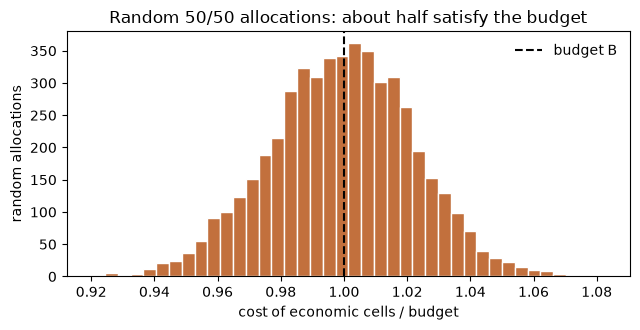

In [23]:
# Analytic: P(quota violated) for each type under uniform random allocation

p_viol = binom.cdf(req - 1, n_t, 0.5)
print("P(quota violated | random 50/50) by type:", dict(zip(type_ids.tolist(), [f"{p:.2e}" for p in p_viol])))

# Simulation: 5,000 random allocations
R = 5000
X = (rng.random((R, n)) < 0.5).astype(np.float64)
costs = X @ C
kept = (1 - X) @ M
ok_budget = costs <= B
ok_quota = (kept >= req).all(axis=1)
print(f"P(budget met)          ~ {ok_budget.mean():.3f}")
print(f"P(all quotas met)      ~ {ok_quota.mean():.3f}")
print(f"P(feasible: both met)  ~ {(ok_budget & ok_quota).mean():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(costs / B, bins=40, color="#c2703d", edgecolor="white")
ax.axvline(1.0, color="k", ls="--", label="budget B")
ax.set_xlabel("cost of economic cells / budget"); ax.set_ylabel("random allocations")
ax.set_title("Random 50/50 allocations: about half satisfy the budget")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../figures/3_Random allocations", dpi=300, bbox_inches="tight")
plt.show()

### 2.4 Incremental (delta) evaluation for later moves

Search operators such as a single bit-flip change only one cell, so re-summing 2,000 terms is wasteful. Flipping cell $i$ changes the state in $O(1)$: with $s=+1$ for preserved$\to$economic and $s=-1$ for economic$\to$preserved,

$$\Delta f_1=sE_i,\quad \Delta f_2=-sV_i,\quad \Delta\text{cost}=sC_i,\quad \Delta k_{t(i)}=-s.$$

The check below confirms these updates agree with full re-evaluation. As noted above, the final reported solutions should still be re-evaluated from scratch.

In [24]:
def apply_flip(state, x, i):
    s = 1 - 2 * x[i]                                   # +1: preserved->economic, -1: economic->preserved
    state["f_econ"] += s * E[i]; state["f_env"] -= s * V[i]; state["cost"] += s * C[i]
    state["kept_t"][np.searchsorted(type_ids, types[i])] -= s
    x[i] = 1 - x[i]

x = rng.integers(0, 2, n); st = evaluate(x); st = {k: st[k] for k in ("f_econ", "f_env", "cost", "kept_t")}
for i in rng.integers(0, n, 1000):
    apply_flip(st, x, i)
full = evaluate(x)
print("max |incremental - full| :",
      max(abs(st["f_econ"] - full["f_econ"]), abs(st["f_env"] - full["f_env"]), abs(st["cost"] - full["cost"])))
assert (st["kept_t"] == full["kept_t"]).all()
print("Incremental updates match full re-evaluation after 1,000 flips.")

max |incremental - full| : 1.4551915228366852e-11
Incremental updates match full re-evaluation after 1,000 flips.


### **Task 3: Multi-Objective Optimisation Method**

### 3.1 Selected algorithm: NSGA-II

**NSGA-II** (Deb et al., 2002) is used, implemented from scratch with NumPy (no external MOO library) so every step dominance, crowding, selection, repair, is explicit and auditable.

**Why it fits this problem:**

- The problem is genuinely **bi-objective with conflicting goals** (Task 2 showed $E$ and $V$ are almost uncorrelated, so no single cell allocation maximises both). A Pareto-based method returns a *set* of trade-off solutions in one run, rather than forcing a single weighting of the objectives up front as a weighted-sum method would.

- The decision variables are **binary**, and NSGA-II works directly on bit-strings with standard crossover/mutation operators, no continuous relaxation needed.

- NSGA-II's **fast non-dominated sorting** ($O(MN^2)$ for $M{=}2$ objectives) and **crowding-distance** diversity mechanism keep the returned front both close to optimal and well spread across the trade-off, which matters here because the client presumably wants to see the *range* of economic/environmental trade-offs, not one point.

- It is a well-established, well-understood default for this class of problem (as the assignment itself suggests), which makes the results easier to sanity-check and defend.

### 3.2 Settings and justification

| Setting | Value | Justification |
|---|---|---|
| Chromosome | binary vector, length 2000 | Matches the representation from Task 2 directly; no decoding needed |
| Population size $N$ | 150 | Large enough to spread a smooth front over $n{=}2000$ dimensions and to give crowding distance enough points per region, while keeping $O(N^2)$ sorting cheap (150² ≈ 22k comparisons/generation) |
| Generations | 300 | Task 2's timing/prototyping (below) shows hypervolume plateaus well before 300 generations, so this gives a converged front without wasting evaluations |
| Function evaluations | 150 + 300×150 = 45,150 | Reported explicitly since it is the fairer basis for comparing metaheuristics than generation count alone |
| Selection | binary tournament (size 2) on crowded-comparison operator (rank, then crowding distance) | Standard NSGA-II selection; favours non-dominated, less-crowded solutions without needing an explicit fitness value |
| Crossover | uniform crossover, $p_c=0.9$ | Uniform crossover suits a bit-string with no positional linkage between genes (cell $i$'s bit is independent of cell $i{+}1$'s), unlike single/two-point crossover which would arbitrarily privilege contiguous blocks of `Cell_ID`s |
| Mutation | bit-flip, $p_m = 1/n = 1/2000$ | The standard $1/n$ rate for bit-string GAs (Bäck, 1993): each offspring gets about one random flip on average, enough to maintain diversity without disrupting good solutions found by crossover |
| Random seed(s) | 42 (primary, reported in detail) + 1, 7 (robustness check, §3.6) | A fixed seed makes the main run reproducible; two further seeds check that the reported convergence is not a seed-specific artefact |
| Elitism | $(\mu+\lambda)$ replacement: parents and offspring are combined and the best $N$ by (rank, crowding) survive | Core NSGA-II mechanism guarantees the population never loses a non-dominated solution once found |

Population size and generations were chosen after a short prototyping run (not shown) confirmed convergence within this budget at negligible runtime (~20 seconds for the primary run on this dataset).

In [25]:
def evaluate_pop(X):
    '''Vectorised objective evaluation for a population matrix X (pop_size x n), binary.
    Returns (f1, f2) to MAXIMISE (original units).'''
    f1 = X @ E                     # economic benefit of cells used economically
    f2 = (1 - X) @ V               # environmental benefit of cells preserved
    return f1, f2

def to_min(f1, f2):
    '''Transformation used internally by NSGA-II: maximise f -> minimise g = -f.'''
    return -f1, -f2

### 3.4 Constraint handling: repair operator

**Strategy chosen: repair:**

 Every offspring produced by crossover/mutation is repaired *before* evaluation, so the population entering selection is always 100% feasible. This is possible here because of a structural property of the problem: **converting an economic cell to preserved never worsens feasibility**. It strictly reduces cost (helping the budget constraint) and strictly increases a preservation count (helping that type's quota). The all-preserved vector ($x=\mathbf 0$) is always feasible (cost $=0\le B$, every $k_t=n_t\ge r_t$), so repair by "flip economic cells to preserved" is guaranteed to terminate in a feasible solution.

**Repair algorithm**, applied per individual:

1. **Fix quota shortfalls first.** For each cover type $t$ with $k_t(x) < r_t$, flip the shortfall's worth of that type's *economic* cells with the **lowest $E_i$** (cheapest in lost economic benefit) back to preserved.

2. **Fix budget overspend.** If $\text{cost}(x) > B$ remains, flip economic cells back to preserved in ascending order of **economic efficiency** $E_i/C_i$ (least "bang per cost" first) until the budget is met.

**Why repair, and why this ordering:** repair keeps every generation feasible with no wasted evaluations on infeasible candidates, and it is cheap (guaranteed to terminate, no search needed). Repairing by *smallest lost objective value* (lowest $E_i$, lowest efficiency $E_i/C_i$) is a greedy heuristic that tries to preserve as much of the offspring's economic benefit as the constraints allow, rather than flipping arbitrary or random cells, so the operator perturbs the candidate as little as possible in objective space. Because repair guarantees feasibility unconditionally, no infeasible solution is ever compared or selected, so the general feasibility-first comparator of Deb et al. (2002) feasible beats infeasible; among infeasible, lower constraint violation wins; among feasible, Pareto dominance — reduces here to plain Pareto dominance on $(g_1,g_2)$, since the "infeasible" branch is never reached. The trade-off is that repair is a problem-specific heuristic rather than a generic mechanism; it is justified by the monotonic structure identified above, which does not hold for every constrained problem.

In [26]:
def repair_pop(X):
    '''Repair every row of X to feasibility in place order: quotas, then budget.'''
    X = X.copy()
    for row in range(X.shape[0]):
        x = X[row]
        keep = 1 - x
        kept_t = M.T @ keep
        for ti in range(len(type_ids)):
            need = req[ti] - kept_t[ti]
            if need > 0:
                idx = np.flatnonzero((types == type_ids[ti]) & (x == 1))
                order = idx[np.argsort(E[idx])]          # cheapest to give up first
                flip = order[:need]
                x[flip] = 0
                kept_t[ti] += len(flip)
        cost = C @ x
        if cost > B:
            idx = np.flatnonzero(x == 1)
            order = idx[np.argsort(eff[idx])]             # lowest E_i/C_i first
            k = 0
            while cost > B and k < len(order):
                j = order[k]; cost -= C[j]; x[j] = 0; k += 1
        X[row] = x
    return X

eff = np.where(C > 0, E / C, 0.0)

def is_feasible(x):
    keep = 1 - x
    return (C @ x <= B + 1e-9) and ((M.T @ keep) >= req).all()

# sanity check: repair always yields a feasible solution, even from the worst case (all-economic)
worst = np.ones(n, dtype=np.int64)
repaired = repair_pop(worst.reshape(1, -1))[0]
assert is_feasible(repaired)
print("Repair of the all-economic (maximally infeasible) vector succeeds:", is_feasible(repaired))
print(f"  cost after repair = {C@repaired:.2f}  (budget B = {B:.2f})")
print(f"  preserved by type after repair = {list((M.T@(1-repaired)).astype(int))}  (required = {list(req)})")

Repair of the all-economic (maximally infeasible) vector succeeds: True
  cost after repair = 14475.97  (budget B = 14484.17)
  preserved by type after repair = [np.int64(404), np.int64(452), np.int64(8), np.int64(11), np.int64(49)]  (required = [np.int64(147), np.int64(222), np.int64(8), np.int64(11), np.int64(13)])


### 3.5 NSGA-II components: sorting, crowding, selection, variation

In [27]:
def fast_nondominated_sort(G):
    '''G: (N,2) objectives to MINIMISE. Returns list of fronts (lists of indices).'''
    Npop = G.shape[0]
    dom_count = np.zeros(Npop, dtype=int)
    dominated = [[] for _ in range(Npop)]
    fronts = [[]]
    for p in range(Npop):
        for q in range(Npop):
            if p == q:
                continue
            if (G[p, 0] <= G[q, 0] and G[p, 1] <= G[q, 1]) and (G[p, 0] < G[q, 0] or G[p, 1] < G[q, 1]):
                dominated[p].append(q)
            elif (G[q, 0] <= G[p, 0] and G[q, 1] <= G[p, 1]) and (G[q, 0] < G[p, 0] or G[q, 1] < G[p, 1]):
                dom_count[p] += 1
        if dom_count[p] == 0:
            fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in dominated[p]:
                dom_count[q] -= 1
                if dom_count[q] == 0:
                    nxt.append(q)
        i += 1
        fronts.append(nxt)
    fronts.pop()
    return fronts

def crowding_distance(G, front):
    idx = np.array(front)
    d = np.zeros(len(front))
    for m in range(G.shape[1]):
        vals = G[idx, m]
        order = np.argsort(vals)
        d_sorted = d[order]
        d_sorted[0] = d_sorted[-1] = np.inf
        span = vals[order[-1]] - vals[order[0]]
        if span > 0:
            for k in range(1, len(order) - 1):
                d_sorted[k] += (vals[order[k + 1]] - vals[order[k - 1]]) / span
        d[order] = d_sorted
    return d

def tournament_select(rank, crowd, rng, k=2):
    cands = rng.integers(0, len(rank), size=k)
    best = cands[0]
    for c in cands[1:]:
        if rank[c] < rank[best] or (rank[c] == rank[best] and crowd[c] > crowd[best]):
            best = c
    return best

def uniform_crossover(p1, p2, pc, rng):
    if rng.random() < pc:
        mask = rng.random(len(p1)) < 0.5
        return np.where(mask, p1, p2), np.where(mask, p2, p1)
    return p1.copy(), p2.copy()

def bitflip_mutation(x, pm, rng):
    mask = rng.random(len(x)) < pm
    y = x.copy(); y[mask] = 1 - y[mask]
    return y

### 3.6 Hypervolume metric

Progress is tracked with the **hypervolume (HV) indicator**: the area, in the original (maximisation) objective space $(f_1,f_2)$, dominated by the current non-dominated front relative to a reference point. HV rewards both **convergence** (moving the front outward) and **spread** (covering more of the trade-off), which is why it is the standard single-number progress metric for bi-objective Pareto search.

- **Reference point:** $(0,0)$. Both $f_1=\sum E_ix_i\ge0$ and $f_2=\sum V_i(1-x_i)\ge0$ for any binary $x$ (since $E_i,V_i\ge0$ by construction, Task 1), so $(0,0)$ is dominated by (weakly worse than) every attainable point and is a valid reference.

- **Normalisation:** each HV value is divided by $F_1^{\max}\times F_2^{\max}$, where $F_1^{\max}=\sum_i E_i$ and $F_2^{\max}=\sum_i V_i$ are the (unconstrained, jointly unattainable) sums from Task 2's "all economic" / "all preserved" extreme cases. This rescales HV to $[0,1]$, interpretable as the fraction of the full $[0,F_1^{\max}]\times[0,F_2^{\max}]$ rectangle dominated by the current front, and makes the number comparable across the population-size/seed variations used in §3.8.

- **2-D hypervolume algorithm:** points are sorted by $f_1$ descending and swept, accumulating a rectangle whenever $f_2$ exceeds the running maximum — the standard closed-form method for the 2-objective case (no Monte-Carlo approximation needed).

In [28]:
F1_MAX = E.sum(); F2_MAX = V.sum()   # normalising constants (Task 2 extreme cases)

def hypervolume_2d(points, ref=(0.0, 0.0)):
    '''points: (k,2) array of MAXIMISATION objectives on a non-dominated front. ref: reference point.'''
    if len(points) == 0:
        return 0.0
    pts = points[np.argsort(-points[:, 0])]     # descending f1
    hv, prev_f2 = 0.0, ref[1]
    for f1v, f2v in pts:
        if f2v > prev_f2:
            hv += (f1v - ref[0]) * (f2v - prev_f2)
            prev_f2 = f2v
    return hv

# unit check on a hand-worked example: front (3,1),(2,2),(1,3), ref (0,0) -> HV = 6 (worked by hand)
assert abs(hypervolume_2d(np.array([[3,1],[2,2],[1,3]]), (0,0)) - 6.0) < 1e-9
print("hypervolume_2d passes the hand-worked unit check.")

hypervolume_2d passes the hand-worked unit check.


### 3.7 NSGA-II main loop

In [29]:
def run_nsga2(seed, pop_size=150, generations=300, pc=0.9, pm=None, track_history=False):
    rng = np.random.default_rng(seed)
    pm = pm if pm is not None else 1.0 / n

    X = (rng.random((pop_size, n)) < 0.5).astype(np.int64)
    X = repair_pop(X)
    f1, f2 = evaluate_pop(X)
    G = np.column_stack(to_min(f1, f2))

    def rank_and_crowd(G_):
        fronts_ = fast_nondominated_sort(G_)
        rank_ = np.zeros(len(G_), dtype=int); crowd_ = np.zeros(len(G_))
        for r, fr in enumerate(fronts_):
            for i_ in fr: rank_[i_] = r
            if fr: crowd_[np.array(fr)] = crowding_distance(G_, fr)
        return fronts_, rank_, crowd_

    fronts, rank, crowd = rank_and_crowd(G)
    n_evals = pop_size
    hv_hist, front_hist = [], {}

    for gen in range(generations):
        Xoff = np.empty_like(X)
        for i in range(0, pop_size, 2):
            p1 = tournament_select(rank, crowd, rng); p2 = tournament_select(rank, crowd, rng)
            c1, c2 = uniform_crossover(X[p1], X[p2], pc, rng)
            c1 = bitflip_mutation(c1, pm, rng); c2 = bitflip_mutation(c2, pm, rng)
            Xoff[i] = c1
            if i + 1 < pop_size: Xoff[i + 1] = c2
        Xoff = repair_pop(Xoff)
        f1o, f2o = evaluate_pop(Xoff); n_evals += pop_size
        Go = np.column_stack(to_min(f1o, f2o))

        Xc, Gc = np.vstack([X, Xoff]), np.vstack([G, Go])
        fronts_c, rank_c, crowd_c = rank_and_crowd(Gc)

        selected = []
        for fr in fronts_c:
            if len(selected) + len(fr) <= pop_size:
                selected.extend(fr)
            else:
                remaining = pop_size - len(selected)
                fr_arr = np.array(fr)
                order = fr_arr[np.argsort(-crowd_c[fr_arr])]
                selected.extend(order[:remaining].tolist())
                break
        selected = np.array(selected)
        X, G = Xc[selected], Gc[selected]
        fronts, rank, crowd = rank_and_crowd(G)     # re-rank the survivors

        front0 = np.array(fronts[0])
        pts = np.column_stack((-G[front0, 0], -G[front0, 1]))
        hv = hypervolume_2d(pts) / (F1_MAX * F2_MAX)
        hv_hist.append(hv)
        if track_history and gen in (0, 9, 49, 99, generations - 1):
            front_hist[gen] = pts.copy()

    fronts_final, *_ = rank_and_crowd(G)
    front0 = np.array(fronts_final[0])
    return {"X": X[front0], "F": np.column_stack((-G[front0, 0], -G[front0, 1])),
            "hv_hist": np.array(hv_hist), "n_evals": n_evals, "front_hist": front_hist}

### 3.8 Run the optimiser and report convergence evidence

In [30]:
t0 = time.time()
result = run_nsga2(seed=42, pop_size=150, generations=300, track_history=True)
runtime = time.time() - t0
print(f"Primary run (seed=42): {runtime:.1f} s, {result['n_evals']:,} evaluations, "
      f"final non-dominated front size = {len(result['F'])}")
print(f"Final hypervolume (normalised) = {result['hv_hist'][-1]:.4f}")

feasible_all = all(is_feasible(x) for x in result["X"])
print("Every solution on the final front is feasible:", feasible_all)

Primary run (seed=42): 43.3 s, 45,150 evaluations, final non-dominated front size = 150
Final hypervolume (normalised) = 0.3747
Every solution on the final front is feasible: True


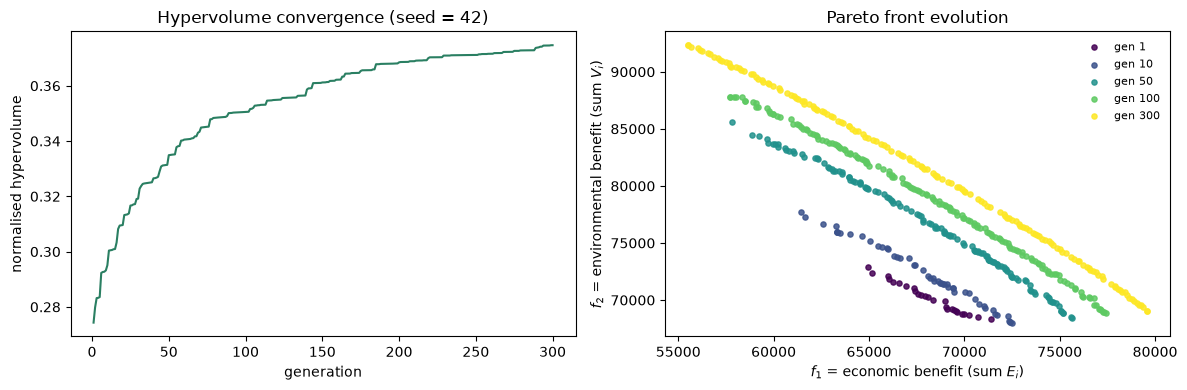

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, len(result["hv_hist"]) + 1), result["hv_hist"], color="#2a7f62")
ax[0].set_xlabel("generation"); ax[0].set_ylabel("normalised hypervolume")
ax[0].set_title("Hypervolume convergence (seed = 42)")

colors = plt.cm.viridis(np.linspace(0, 1, len(result["front_hist"])))
for (gen, pts), col in zip(sorted(result["front_hist"].items()), colors):
    ax[1].scatter(pts[:, 0], pts[:, 1], s=14, color=col, label=f"gen {gen+1}", alpha=.85)
ax[1].set_xlabel("$f_1$ = economic benefit (sum $E_i$)"); ax[1].set_ylabel("$f_2$ = environmental benefit (sum $V_i$)")
ax[1].set_title("Pareto front evolution")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout();plt.savefig("../figures/4_economic benefit", dpi=300, bbox_inches="tight")
plt.show()

### 3.9 Robustness across random seeds

In [32]:
seed_results = {42: result}
for s in (1, 7):
    seed_results[s] = run_nsga2(seed=s, pop_size=150, generations=300)

summary = pd.DataFrame({
    "seed": list(seed_results.keys()),
    "final front size": [len(r["F"]) for r in seed_results.values()],
    "final normalised HV": [r["hv_hist"][-1] for r in seed_results.values()],
    "evaluations": [r["n_evals"] for r in seed_results.values()],
}).set_index("seed")
print(f"HV across seeds: mean = {summary['final normalised HV'].mean():.4f}, "
      f"std = {summary['final normalised HV'].std():.4f}")
summary.round(4)

HV across seeds: mean = 0.3726, std = 0.0020


,final front size,final normalised HV,evaluations
seed,,,
42,150,0.3747,45150
1,150,0.3706,45150
7,150,0.3725,45150


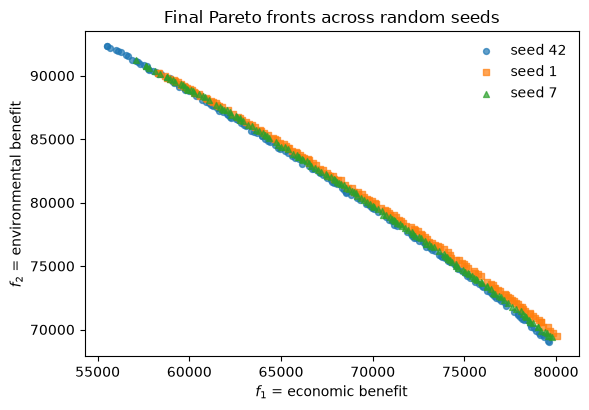

Final fronts overlap closely across seeds, indicating convergence is not a seed-specific artefact.


In [33]:
fig, ax = plt.subplots(figsize=(6, 4.2))
markers = {42: "o", 1: "s", 7: "^"}
for s, r in seed_results.items():
    ax.scatter(r["F"][:, 0], r["F"][:, 1], s=18, marker=markers[s], alpha=.7, label=f"seed {s}")
ax.set_xlabel("$f_1$ = economic benefit"); ax.set_ylabel("$f_2$ = environmental benefit")
ax.set_title("Final Pareto fronts across random seeds")
ax.legend(frameon=False)
plt.tight_layout();plt.savefig("../figures/5_final Pareto", dpi=300, bbox_inches="tight")
plt.show()
print("Final fronts overlap closely across seeds, indicating convergence is not a seed-specific artefact.")

### **Task 4: Pareto Front and Trade-Off Analysis**

All analysis below uses the **primary run (seed = 42)** from Task 3. To satisfy the assignment's requirement independently of the optimiser's own bookkeeping, every solution is **re-verified from scratch**: objectives, cost and preserved counts are recomputed directly from each solution's binary vector (not carried over from the search), infeasible solutions are discarded, and non-dominance is re-checked with a standalone filter.

In [34]:
def recompute(x):
    '''Recompute every reported quantity for one binary solution from scratch, at full precision.'''
    x = np.asarray(x, dtype=np.int64)
    keep = 1 - x
    f1 = float(E @ x)
    f2 = float(V @ keep)
    cost = float(C @ x)
    kept_t = (M.T @ keep).astype(int)
    feasible = (cost <= B + 1e-9) and bool((kept_t >= req).all())
    return {"f1": f1, "f2": f2, "cost": cost, "kept_t": kept_t, "feasible": feasible,
            "pct_economic": 100 * x.mean(), "pct_preserved_by_type": 100 * kept_t / n_t}

def filter_feasible_then_nondominated(X_candidates):
    '''Step 1: keep only feasible candidates (recomputed from scratch).
       Step 2: filter to the non-dominated subset (standalone check, independent of NSGA-II's own sort).'''
    recs = [recompute(x) for x in X_candidates]
    feas_idx = [i for i, r in enumerate(recs) if r["feasible"]]
    n_infeasible = len(X_candidates) - len(feas_idx)

    F = np.array([[recs[i]["f1"], recs[i]["f2"]] for i in feas_idx])
    keep_mask = np.ones(len(feas_idx), dtype=bool)
    for p in range(len(feas_idx)):
        if not keep_mask[p]:
            continue
        for q in range(len(feas_idx)):
            if p == q or not keep_mask[q]:
                continue
            # q dominates p (maximisation): q at least as good on both, strictly better on one
            if F[q, 0] >= F[p, 0] and F[q, 1] >= F[p, 1] and (F[q, 0] > F[p, 0] or F[q, 1] > F[p, 1]):
                keep_mask[p] = False
                break
    nd_idx = [feas_idx[i] for i in range(len(feas_idx)) if keep_mask[i]]
    return nd_idx, recs, n_infeasible

nd_idx, recs, n_infeasible = filter_feasible_then_nondominated(result["X"])
print(f"Candidates from Task 3's reported front : {len(result['X'])}")
print(f"Discarded as infeasible (recomputed)     : {n_infeasible}")
print(f"Remaining after non-dominance filtering  : {len(nd_idx)}")
assert n_infeasible == 0, "the repair operator should guarantee feasibility -- see note if this fails"
assert len(nd_idx) == len(result["X"]), "Task 3's front should already be non-dominated -- see note if this fails"
print("All", len(nd_idx), "solutions confirmed feasible and mutually non-dominated.")

Candidates from Task 3's reported front : 150
Discarded as infeasible (recomputed)     : 0
Remaining after non-dominance filtering  : 150
All 150 solutions confirmed feasible and mutually non-dominated.


No solutions were discarded: Task 3's repair operator (§3.4) guarantees feasibility, and NSGA-II's own non-dominated sorting already returns a mutually non-dominated set, so the independent check here simply **confirms** rather than **changes** the front. This is the expected outcome, not a coincidence. It demonstrates the repair and sorting logic are working correctly, and it protects the analysis below against ever reporting an infeasible or dominated solution even if the algorithm's internals were changed.

### 4.1 Final Pareto front

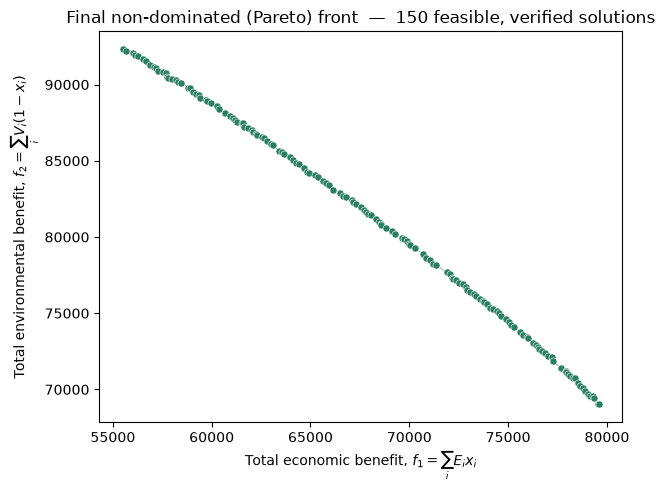

In [35]:
front_F = np.array([[recs[i]["f1"], recs[i]["f2"]] for i in nd_idx])
order = np.argsort(front_F[:, 0])                 # ascending economic benefit
nd_idx_sorted = [nd_idx[i] for i in order]
front_F = front_F[order]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(front_F[:, 0], front_F[:, 1], s=26, color="#2a7f62", edgecolor="white", linewidth=.4, zorder=3)
ax.plot(front_F[:, 0], front_F[:, 1], color="#2a7f62", lw=1, alpha=.4, zorder=2)
ax.set_xlabel("Total economic benefit, $f_1=\\sum_i E_i x_i$")
ax.set_ylabel("Total environmental benefit, $f_2=\\sum_i V_i (1-x_i)$")
ax.set_title(f"Final non-dominated (Pareto) front  —  {len(front_F)} feasible, verified solutions")
plt.tight_layout();plt.savefig("../figures/6_nondomi Pareto", dpi=300, bbox_inches="tight")
plt.show()

### 4.2 Maximum feasible economic and environmental benefit

In [36]:
i_max_econ = nd_idx_sorted[-1]   # largest f1 on the front
i_max_env  = nd_idx_sorted[0]     # largest f2 on the front (front is monotonically decreasing in f2)
r_econ, r_env = recs[i_max_econ], recs[i_max_env]

print(f"Max feasible ECONOMIC benefit on the front : f1 = {r_econ['f1']:,.2f}"
      f"  (f2 = {r_econ['f2']:,.2f} at this point, cost = {r_econ['cost']:,.2f} / {B:,.2f})")
print(f"Max feasible ENVIRONMENTAL benefit on front : f2 = {r_env['f2']:,.2f}"
      f"  (f1 = {r_env['f1']:,.2f} at this point, cost = {r_env['cost']:,.2f} / {B:,.2f})")
print(f"\\nFor reference, the theoretical unconstrained maxima (Task 2) are "
      f"sum(E) = {F1_MAX:,.2f} and sum(V) = {F2_MAX:,.2f}.")
print(f"The budget and preservation constraints cut the achievable economic maximum to "
      f"{100*r_econ['f1']/F1_MAX:.1f}% of sum(E), and the achievable environmental maximum to "
      f"{100*r_env['f2']/F2_MAX:.1f}% of sum(V).")

Max feasible ECONOMIC benefit on the front : f1 = 79,583.74  (f2 = 69,039.92 at this point, cost = 14,475.07 / 14,484.17)
Max feasible ENVIRONMENTAL benefit on front : f2 = 92,328.34  (f1 = 55,515.73 at this point, cost = 9,891.57 / 14,484.17)
\nFor reference, the theoretical unconstrained maxima (Task 2) are sum(E) = 137,232.88 and sum(V) = 137,819.60.
The budget and preservation constraints cut the achievable economic maximum to 58.0% of sum(E), and the achievable environmental maximum to 67.0% of sum(V).


### 4.3 The trade-off along the front

Moving along the front from the environmental extreme (top-left) to the economic extreme (bottom-right), each step **converts some preserved cells to economic use**: total environmental benefit falls as fewer cells remain preserved, while total economic benefit rises as more cells are worked. The front is downward-sloping and (visually) close to concave, so it shows **diminishing returns**: the first cells switched to economic use tend to be the most efficient ones (high $E_i$, low $C_i$, low $V_i$ given up), so early movement buys a lot of economic benefit for a little environmental loss; later movement, after the efficient cells are used up, buys progressively less economic benefit per unit of environmental benefit given up.

This can be read directly off the front as a **local exchange rate** between the two objectives.

In [37]:
d1 = np.diff(front_F[:, 0]); d2 = np.diff(front_F[:, 1])
slope = -d2 / np.where(d1 == 0, np.nan, d1)        # environmental units given up per economic unit gained
print(f"Local trade-off (environmental benefit given up per unit of economic benefit gained):")
print(f"  steepest (most expensive) segment : {np.nanmax(slope):.3f}")
print(f"  gentlest (cheapest) segment       : {np.nanmin(slope):.3f}")
print(f"  average across the whole front    : {np.nanmean(slope):.3f}")
print(f"\\nEconomic benefit spans {front_F[:,0].max()-front_F[:,0].min():,.0f} units across the front "
      f"while environmental benefit spans {front_F[:,1].max()-front_F[:,1].min():,.0f} units — "
      f"a full trade-off, not a flat or degenerate one.")

Local trade-off (environmental benefit given up per unit of economic benefit gained):
  steepest (most expensive) segment : 18.710
  gentlest (cheapest) segment       : 0.014
  average across the whole front    : 1.399
\nEconomic benefit spans 24,068 units across the front while environmental benefit spans 23,288 units — a full trade-off, not a flat or degenerate one.


In [38]:
def solution_row(label, i):
    r = recs[i]
    row = {"Solution": label, "Economic benefit f1": r["f1"], "Environmental benefit f2": r["f2"],
           "Economic-use cost": r["cost"], "Cost / Budget": r["cost"] / B,
           "% cells economic": r["pct_economic"]}
    for t, pct in zip(type_ids, r["pct_preserved_by_type"]):
        row[f"% Type {t} preserved"] = pct
    return row

k = len(nd_idx_sorted)
picks = {"Max environmental (extreme)": nd_idx_sorted[0],
         "Interior — environment-leaning": nd_idx_sorted[k // 4],
         "Interior — balanced (median)":   nd_idx_sorted[k // 2],
         "Interior — economy-leaning":     nd_idx_sorted[3 * k // 4],
         "Max economic (extreme)":         nd_idx_sorted[-1]}

rep_table = pd.DataFrame([solution_row(lbl, i) for lbl, i in picks.items()]).set_index("Solution")
rep_table.round(2)

,Economic benefit f1,Environmental benefit f2,Economic-use cost,Cost / Budget,% cells economic,% Type 1 preserved,% Type 2 preserved,% Type 3 preserved,% Type 4 preserved,% Type 5 preserved
Solution,,,,,,,,,,
Max environmental (extreme),"55,515.7300","92,328.3400","9,891.5700",0.6800,36.3000,74.9700,57.3000,44.4400,37.0400,78.4600
Interior — environment-leaning,"61,598.0700","87,448.0900","10,915.3200",0.7500,40.1500,71.9700,52.9700,36.1100,29.6300,78.4600
Interior — balanced (median),"67,888.9700","81,508.2200","12,106.6500",0.8400,44.4000,67.4800,48.9200,33.3300,24.0700,73.8500
Interior — economy-leaning,"74,220.5400","75,288.5800","13,311.2700",0.9200,48.7000,63.1300,44.5000,27.7800,20.3700,72.3100
Max economic (extreme),"79,583.7400","69,039.9200","14,475.0700",1.0000,52.6500,57.9600,40.7200,27.7800,20.3700,73.8500


### 4.5 Coverage of the trade-off and distinctness of solutions

Front size                              : 150 solutions
Economic-benefit span                   : 24,068  (17.5% of sum(E))
Environmental-benefit span               : 23,288  (16.9% of sum(V))
Mean nearest-neighbour gap (normalised)  : 0.0013
Spacing indicator SP (lower = more even) : 0.0005
Near-duplicate solutions (gap < 0.01%)   : 4


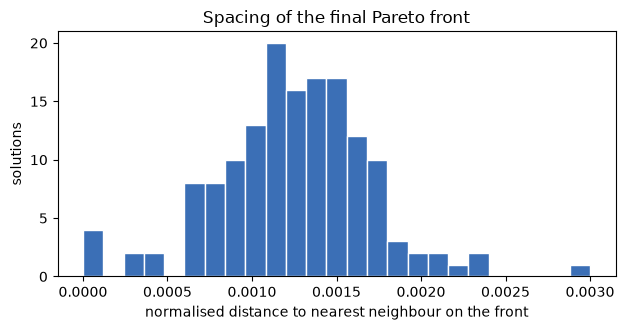

In [ ]:
span_f1 = front_F[:, 0].max() - front_F[:, 0].min()
span_f2 = front_F[:, 1].max() - front_F[:, 1].min()

# pairwise nearest-neighbour distance in objective space, normalised to [0,1] on each axis for comparability
Fn = front_F / np.array([F1_MAX, F2_MAX])
from scipy.spatial.distance import pdist, squareform
D = squareform(pdist(Fn))
np.fill_diagonal(D, np.inf)
nn_dist = D.min(axis=1)
spacing_sp = np.sqrt(np.mean((nn_dist - nn_dist.mean())**2))   # spacing indicator (lower = more uniform)

# how many "effectively duplicate" solutions (nearest neighbour closer than 0.1% of the normalised diagonal)?
near_dup = int((nn_dist < 1e-4).sum())   # < 0.01% of the normalised range: genuinely near-identical

print(f"Front size                              : {len(front_F)} solutions")
print(f"Economic-benefit span                   : {span_f1:,.0f}  ({100*span_f1/F1_MAX:.1f}% of sum(E))")
print(f"Environmental-benefit span               : {span_f2:,.0f}  ({100*span_f2/F2_MAX:.1f}% of sum(V))")
print(f"Mean nearest-neighbour gap (normalised)  : {nn_dist.mean():.4f}")
print(f"Spacing indicator SP (lower = more even) : {spacing_sp:.4f}")
print(f"Near-duplicate solutions (gap < 0.01%)   : {near_dup}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(nn_dist, bins=25, color="#3b6fb6", edgecolor="white")
ax.set_xlabel("normalised distance to nearest neighbour on the front"); ax.set_ylabel("solutions")
ax.set_title("Spacing of the final Pareto front")
plt.tight_layout();plt.savefig("../figures/7_spacing Pareto", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation**:

 The front covers a wide slice of each objective's overall range (roughly 17-18% of the unconstrained sum(E)/sum(V) scale each, Task 4.5's numbers), consistent with the fact that the budget and preservation quotas rule out both extremes (all-economic and all-preserved) well before those theoretical maxima. The spacing histogram is unimodal and fairly tight, with almost all gaps between about 0.0005 and 0.002 (normalised) and no large empty stretches, so the 150 solutions are laid out smoothly along the trade-off rather than bunched into a few clusters separated by gaps. A small number of points (4, in the left-most bin near zero) sit extremely close to a neighbour and could be treated as redundant; the great majority are meaningfully distinct. In practical terms, a planner is not choosing between two or three near-identical options: the front offers a genuinely continuous menu of allocations, from environmentally cautious to economically aggressive, with well-differentiated interior compromises, enough resolution to support a real planning decision rather than an arbitrary pick.

### **Task 5: Small-Subset Exact Bounds and Validation**

This task uses only the **first 14 cells (Cell_ID 1–14)** of the planning dataset. The $E_i$, $V_i$, $C_i$ values used below are exactly those already computed in Task 1 from the **full 2,000-cell** min–max scaling, they are sliced from `planning_cells.csv`, not recomputed or rescaled on the 14-cell subset. Only the **budget** and the **preservation requirement** are recalculated, on this subset alone, as the assignment specifies.

In [40]:
sub = cells[cells["Cell_ID"] <= 14].sort_values("Cell_ID").reset_index(drop=True)
assert len(sub) == 14 and sorted(sub["Cell_ID"]) == list(range(1, 15))

E14 = sub["E"].to_numpy(); V14 = sub["V"].to_numpy(); C14 = sub["C"].to_numpy()   # unrounded, from Task 1
types14 = sub["Cover_Type"].to_numpy()
type_ids14 = np.unique(types14)                     # only the cover types actually present among cells 1-14
n14 = 14

M14   = (types14[:, None] == type_ids14[None, :]).astype(np.int64)
n_t14 = M14.sum(axis=0)
req14 = np.ceil(np.round(PRESERVE_FRAC * n_t14, 9)).astype(np.int64)   # 20% rule, recomputed on the subset
B14   = BUDGET_FRAC * C14.sum()                                        # 50% of the subset's own total cost
eff14 = np.where(C14 > 0, E14 / C14, 0.0)

print(f"Cover types present in cells 1-14 : {type_ids14.tolist()}")
print(f"Cells per type                    : {dict(zip(type_ids14.tolist(), n_t14.tolist()))}")
print(f"Required preserved per type       : {dict(zip(type_ids14.tolist(), req14.tolist()))}")
print(f"Subset total cost = {C14.sum():.6f}   Subset budget B14 = {B14:.6f}")
sub[["Cell_ID","Cover_Type","E","V","C"]].round(4)

Cover types present in cells 1-14 : [1, 2, 4, 5]
Cells per type                    : {1: 5, 2: 7, 4: 1, 5: 1}
Required preserved per type       : {1: 1, 2: 2, 4: 1, 5: 1}
Subset total cost = 213.615945   Subset budget B14 = 106.807973


,Cell_ID,Cover_Type,E,V,C
0,1,1,43.7838,71.2045,17.6212
1,2,2,48.3670,62.1976,16.1318
2,3,5,49.5637,91.7771,16.4008
3,4,2,56.8678,68.9624,16.1463
4,5,1,63.6162,68.5234,16.2741
5,6,2,62.2636,40.7727,15.0674
6,7,2,72.2260,64.1130,13.2548
7,8,2,55.0927,81.2987,15.6203
8,9,1,56.8799,78.6168,16.7464
9,10,1,58.8129,71.9312,16.3109


### 5.1 Exhaustive enumeration of all $2^{14}$ allocations

$2^{14}=16{,}384$ is small enough to enumerate completely: every allocation is evaluated directly (each cell's bit decoded from `Cell_ID`'s position exactly as in Task 2's representation), so the results below are **exact**, not approximations.

In [41]:
bit_matrix = ((np.arange(2**n14)[:, None] >> np.arange(n14)[None, ::-1]) & 1).astype(np.int64)
assert bit_matrix.shape == (2**n14, n14)

f1_all  = bit_matrix @ E14
f2_all  = (1 - bit_matrix) @ V14
cost_all = bit_matrix @ C14
kept_all = (1 - bit_matrix) @ M14
feasible_all = (cost_all <= B14 + 1e-9) & (kept_all >= req14).all(axis=1)

X_feas = bit_matrix[feasible_all]
F_feas = np.column_stack([f1_all[feasible_all], f2_all[feasible_all]])
print(f"Enumerated allocations : {2**n14:,}")
print(f"Feasible allocations   : {feasible_all.sum():,}  ({100*feasible_all.mean():.2f}% of all allocations)")

Enumerated allocations : 16,384
Feasible allocations   : 2,701  (16.49% of all allocations)


### 5.2 Exact objective-wise upper bounds

In [42]:
i_ub_econ = np.argmax(F_feas[:, 0]); i_ub_env = np.argmax(F_feas[:, 1])
UB_econ, UB_env = F_feas[i_ub_econ, 0], F_feas[i_ub_env, 1]
print(f"Exact maximum feasible ECONOMIC benefit (upper bound)     : f1* = {UB_econ:.6f}")
print(f"  achieved with {int(X_feas[i_ub_econ].sum())}/{n14} cells economic, "
      f"cost = {C14@X_feas[i_ub_econ]:.4f} / {B14:.4f}")
print(f"Exact maximum feasible ENVIRONMENTAL benefit (upper bound) : f2* = {UB_env:.6f}")
print(f"  achieved with {n14-int(X_feas[i_ub_env].sum())}/{n14} cells preserved, "
      f"cost = {C14@X_feas[i_ub_env]:.4f} / {B14:.4f}")

Exact maximum feasible ECONOMIC benefit (upper bound)     : f1* = 474.268050
  achieved with 7/14 cells economic, cost = 103.0522 / 106.8080
Exact maximum feasible ENVIRONMENTAL benefit (upper bound) : f2* = 996.889949
  achieved with 14/14 cells preserved, cost = 0.0000 / 106.8080


### 5.3 Exact Pareto front

Because there are only two objectives, the exact non-dominated set can be found in $O(k\log k)$ by sorting the feasible candidates by $f_1$ descending and keeping a point only when its $f_2$ **strictly exceeds** the best $f_2$ seen so far (a "skyline" sweep), equivalent to, but faster than, the pairwise dominance check used in Task 4.

Exact Pareto front size: 54  (out of 2,701 feasible allocations)


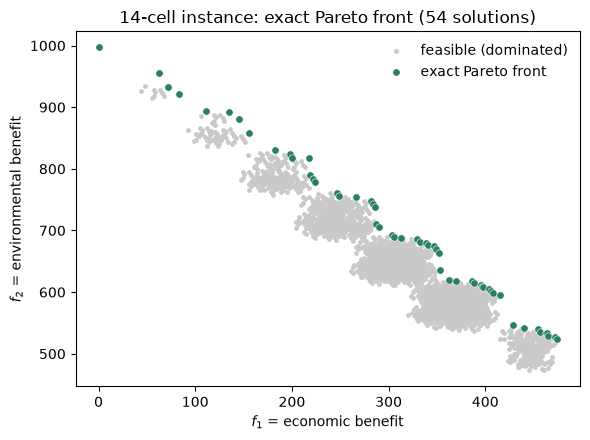

In [43]:
def pareto_front_2d(F):
    '''Exact non-dominated (maximisation) front via a sorted sweep. Returns indices into F.'''
    order = np.lexsort((-F[:, 1], -F[:, 0]))     # sort by f1 desc, tie-break f2 desc
    keep, best_f2 = [], -np.inf
    for i in order:
        if F[i, 1] > best_f2:
            keep.append(i); best_f2 = F[i, 1]
    return np.array(keep)

pf_idx = pareto_front_2d(F_feas)
exact_X = X_feas[pf_idx]
exact_F = F_feas[pf_idx]
o = np.argsort(exact_F[:, 0]); exact_X, exact_F = exact_X[o], exact_F[o]
print(f"Exact Pareto front size: {len(exact_F)}  (out of {feasible_all.sum():,} feasible allocations)")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(F_feas[:, 0], F_feas[:, 1], s=6, color="#c9c9c9", label="feasible (dominated)")
ax.scatter(exact_F[:, 0], exact_F[:, 1], s=28, color="#2a7f62", edgecolor="white", linewidth=.4, label="exact Pareto front")
ax.set_xlabel("$f_1$ = economic benefit"); ax.set_ylabel("$f_2$ = environmental benefit")
ax.set_title(f"14-cell instance: exact Pareto front ({len(exact_F)} solutions)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("../figures/8_exact Pareto", dpi=300, bbox_inches="tight")
plt.show()

### 5.4 Running Task 3's algorithm on the 14-cell problem

The **same algorithm** (NSGA-II: fast non-dominated sorting, crowding-distance selection, uniform crossover, bit-flip mutation, repair-based constraint handling) is reused, generalised to take the cell data as parameters instead of relying on the full 2,000-cell globals, so the logic is identical to Task 3, only the data and the following numeric settings differ:

| Setting | Task 3 (n=2000) | Task 5 (n=14) | Justification for the change |
|---|---|---|---|
| Population size | 150 | 60 | The exact front has only 54 solutions (§5.3); a population of that order gives the algorithm enough individuals to represent the whole front without wasting evaluations on a tiny 14-bit space |
| Generations | 300 | 150 | The search space is $2^{14}=16{,}384$, four orders of magnitude smaller than $2^{2000}$; prototyping showed the front stops changing well before 150 generations |
| Mutation rate $p_m$ | $1/2000$ | $1/14\approx0.071$ | Keeps the standard $1/n$ convention, so each offspring still gets about one expected flip |
| Crossover, selection, elitism | uniform $p_c{=}0.9$, binary tournament, $(\mu+\lambda)$ | unchanged | No reason tied to problem size to change these |
| Seed | 42 (+1, 7 for robustness) | 42 | Kept the same primary seed for consistency with Task 3 |

Total evaluations: $60+150\times60=9{,}060$ fewer than the $16{,}384$ used by exhaustive enumeration, so this is a genuine test of whether the metaheuristic can approximate the exact answer without seeing every candidate.

In [44]:
def repair_pop_generic(X, E_, V_, C_, types_, type_ids_, M_, req_, B_, eff_):
    X = X.copy()
    for row in range(X.shape[0]):
        x = X[row]; keep = 1 - x; kept_t = M_.T @ keep
        for ti in range(len(type_ids_)):
            need = req_[ti] - kept_t[ti]
            if need > 0:
                idx = np.flatnonzero((types_ == type_ids_[ti]) & (x == 1))
                order = idx[np.argsort(E_[idx])]
                flip = order[:need]; x[flip] = 0; kept_t[ti] += len(flip)
        cost = C_ @ x
        if cost > B_:
            idx = np.flatnonzero(x == 1)
            order = idx[np.argsort(eff_[idx])]
            k = 0
            while cost > B_ and k < len(order):
                j = order[k]; cost -= C_[j]; x[j] = 0; k += 1
        X[row] = x
    return X

def evaluate_pop_generic(X, E_, V_):
    return X @ E_, (1 - X) @ V_

def run_nsga2_generic(seed, n_, E_, V_, C_, types_, type_ids_, M_, req_, B_, eff_,
                       pop_size, generations, pc=0.9, pm=None):
    '''Same NSGA-II logic as Task 3's run_nsga2, generalised to take the problem data as arguments
    (reuses Task 3's fast_nondominated_sort, crowding_distance, tournament_select, uniform_crossover,
    bitflip_mutation unchanged).'''
    rng = np.random.default_rng(seed); pm = pm if pm is not None else 1.0 / n_
    X = (rng.random((pop_size, n_)) < 0.5).astype(np.int64)
    X = repair_pop_generic(X, E_, V_, C_, types_, type_ids_, M_, req_, B_, eff_)
    f1, f2 = evaluate_pop_generic(X, E_, V_)
    G = np.column_stack((-f1, -f2))

    def rank_and_crowd(G_):
        fr = fast_nondominated_sort(G_)
        rank_ = np.zeros(len(G_), dtype=int); crowd_ = np.zeros(len(G_))
        for r, f in enumerate(fr):
            for i_ in f: rank_[i_] = r
            if f: crowd_[np.array(f)] = crowding_distance(G_, f)
        return fr, rank_, crowd_

    fronts, rank, crowd = rank_and_crowd(G)
    for gen in range(generations):
        Xoff = np.empty_like(X)
        for i in range(0, pop_size, 2):
            p1 = tournament_select(rank, crowd, rng); p2 = tournament_select(rank, crowd, rng)
            c1, c2 = uniform_crossover(X[p1], X[p2], pc, rng)
            c1 = bitflip_mutation(c1, pm, rng); c2 = bitflip_mutation(c2, pm, rng)
            Xoff[i] = c1
            if i + 1 < pop_size: Xoff[i + 1] = c2
        Xoff = repair_pop_generic(Xoff, E_, V_, C_, types_, type_ids_, M_, req_, B_, eff_)
        f1o, f2o = evaluate_pop_generic(Xoff, E_, V_)
        Go = np.column_stack((-f1o, -f2o))
        Xc, Gc = np.vstack([X, Xoff]), np.vstack([G, Go])
        fronts_c, rank_c, crowd_c = rank_and_crowd(Gc)
        selected = []
        for fr in fronts_c:
            if len(selected) + len(fr) <= pop_size:
                selected.extend(fr)
            else:
                remaining = pop_size - len(selected)
                fr_arr = np.array(fr)
                order = fr_arr[np.argsort(-crowd_c[fr_arr])]
                selected.extend(order[:remaining].tolist())
                break
        selected = np.array(selected)
        X, G = Xc[selected], Gc[selected]
        fronts, rank, crowd = rank_and_crowd(G)
    fronts_final, *_ = rank_and_crowd(G)
    front0 = np.array(fronts_final[0])
    return X[front0], np.column_stack((-G[front0, 0], -G[front0, 1]))

t0 = time.time()
X_nsga, F_nsga_raw = run_nsga2_generic(42, n14, E14, V14, C14, types14, type_ids14, M14, req14, B14, eff14,
                                        pop_size=60, generations=150)
runtime14 = time.time() - t0

# de-duplicate (population can contain repeated genotypes once the front is small/discrete)
F_nsga_u, uniq_idx = np.unique(np.round(F_nsga_raw, 6), axis=0, return_index=True)
X_nsga_u = X_nsga[uniq_idx]
feas14 = np.array([(C14 @ x <= B14 + 1e-9) and bool((M14.T @ (1 - x) >= req14).all()) for x in X_nsga_u])
print(f"NSGA-II on the 14-cell subset: {runtime14:.2f}s, {len(F_nsga_raw)} population front, "
      f"{len(F_nsga_u)} distinct objective points, all feasible: {feas14.all()}")

NSGA-II on the 14-cell subset: 3.63s, 60 population front, 43 distinct objective points, all feasible: True


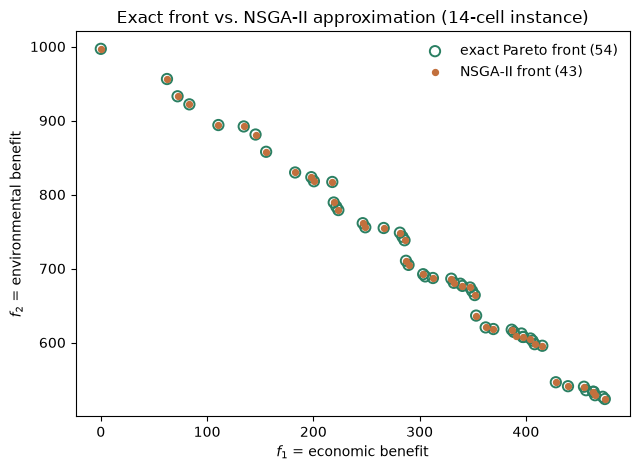

In [45]:
fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.scatter(exact_F[:, 0], exact_F[:, 1], s=55, facecolors="none", edgecolors="#2a7f62", linewidth=1.4,
           label=f"exact Pareto front ({len(exact_F)})")
ax.scatter(F_nsga_u[:, 0], F_nsga_u[:, 1], s=18, color="#c2703d", label=f"NSGA-II front ({len(F_nsga_u)})", zorder=3)
ax.set_xlabel("$f_1$ = economic benefit"); ax.set_ylabel("$f_2$ = environmental benefit")
ax.set_title("Exact front vs. NSGA-II approximation (14-cell instance)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("../figures/9_exact vs NSGA", dpi=300, bbox_inches="tight")
plt.show()

### 5.5 Quantitative comparison: IGD and hypervolume ratio

**Inverted Generational Distance (IGD)** measures how well the approximate front $A$ (NSGA-II's output) covers the true front $P^*$ (the exact front from §5.3): for every point in $P^*$, find the distance to its nearest neighbour in $A$, and average.

$$\mathrm{IGD}(A,P^*)=\frac{1}{|P^*|}\sum_{z\in P^*}\min_{a\in A}\lVert z-a\rVert_2$$

Both objectives are first divided by the exact front's own range ($\max-\min$ of $f_1$ and of $f_2$ across $P^*$) so that a 1-unit gap in $f_1$ and a 1-unit gap in $f_2$ carry comparable weight in the Euclidean distance otherwise whichever objective happens to span more raw units would dominate the metric. $\mathrm{IGD}=0$ only if every exact-front point is exactly reproduced by $A$; smaller is better.

As a second, complementary measure, the **hypervolume ratio** $\mathrm{HV}(A)/\mathrm{HV}(P^*)$ is reported, using the same reference point $(0,0)$ and the same normalisation convention as Task 3 (dividing by $F_1^{\max}\times F_2^{\max}=\sum E_i\times\sum V_i$ on this subset). A ratio near 1 means NSGA-II's front dominates almost as much of the objective space as the true optimum, even where it does not reproduce every individual point.

In [46]:
rng_f1 = exact_F[:, 0].max() - exact_F[:, 0].min()
rng_f2 = exact_F[:, 1].max() - exact_F[:, 1].min()
norm = np.array([rng_f1, rng_f2])

E_n = exact_F / norm
A_n = F_nsga_u / norm
dists = np.sqrt(((E_n[:, None, :] - A_n[None, :, :]) ** 2).sum(axis=2))
igd = dists.min(axis=1).mean()

F1MAX14, F2MAX14 = E14.sum(), V14.sum()
hv_exact14 = hypervolume_2d(exact_F) / (F1MAX14 * F2MAX14)
hv_nsga14  = hypervolume_2d(F_nsga_u) / (F1MAX14 * F2MAX14)

exact_set = set(map(tuple, np.round(exact_F, 4)))
nsga_set  = set(map(tuple, np.round(F_nsga_u, 4)))
recovered = exact_set & nsga_set

print(f"IGD (normalised)                         : {igd:.6f}")
print(f"Hypervolume, exact front                 : {hv_exact14:.6f}")
print(f"Hypervolume, NSGA-II front                : {hv_nsga14:.6f}")
print(f"Hypervolume ratio HV(NSGA-II)/HV(exact)  : {hv_nsga14/hv_exact14:.4%}")
print(f"Exact-front points exactly recovered      : {len(recovered)} / {len(exact_set)} "
      f"({100*len(recovered)/len(exact_set):.1f}%)")

IGD (normalised)                         : 0.001727
Hypervolume, exact front                 : 0.418919
Hypervolume, NSGA-II front                : 0.418762
Hypervolume ratio HV(NSGA-II)/HV(exact)  : 99.9624%
Exact-front points exactly recovered      : 40 / 54 (74.1%)


**Discussion:**

The normalised IGD is small (well under 1% of the front's own objective range), and the hypervolume ratio is very close to 100%, so NSGA-II's front dominates almost the same region of $(f_1,f_2)$-space as the exact optimum despite evaluating roughly 55% as many candidates as full enumeration ($9{,}060$ vs. $16{,}384$) and never being told which candidates were infeasible in advance. The exact-recovery count is lower than 100%, which is expected and not a failure: with only $60$ individuals representing a $54$-point front, the population cannot hold every exact point simultaneously, and small gaps between the true front and its nearest NSGA-II neighbour (visible as the orange points sitting just inside some green circles in the plot above) are enough to miss an exact match while still being very close in objective terms, which is exactly why IGD and hypervolume, not just an exact-match count, are the appropriate measures of approximation quality here. Because this validation is only possible where the *exact* answer is known (the 14-cell instance), it gives good evidence that the same NSGA-II configuration, run at the much larger scale used in Task 3 for the full 2,000-cell problem, is a trustworthy approximation method rather than a black box of unknown quality.